<h2> Infrastructure </h2>

In [ ]:
# Thermal Controller Board Level Prototype
# By Shawn Newman

In [ ]:
# Tips:  
  
# VSCode:
#    * Outline button is in the row of buttons right above this pane. Much easier navigation. You may need to vertically expand it
#    * Click on the blue bar to the left of a cell to hide it. Also works on outputs
#    * Right click on any function call and select "Go to Definition" to jump to the actual function
#
# Jupyter Notebook:
#    * [View->Table of contents] for the outline
#    * You can click the arrow to the left of headings to collapse/expand their section
#
# Structure:
#    * The first code cell "Initialize All" should run every other cell that exclusively defines functions and imports libraries.
#    * The headings in the outline with an asterisk are the ones that actually use those functions, 
#      constants, and libraries to do things. You'll manually run those.
#    * Don't click the little "init" buttons in the bottom left of cells, it erases the tag that "Initialize All" uses to filter.
#
# Misc:
#    * [ctrl+Enter] runs a cell
#    * Select multiple lines of code, then press [ctrl+/] to comment or uncomment all 
#      (I just discovered this a couple months ago and am mad about it)

<h3>* Initialize All Functions & Libraries</h3>

In [1]:
# Turn on File->'Auto Save' if you want to use this. It reads cell data from disk.
# This runs every cell in here with the tag "init". Library imports, function definitions, constants, etc.
# Saves a lot of time. Works well as a redundancy.

import nbformat # Library for manipulating notebooks

def execute_cells_by_tag(group_tag, quiet=True):
    print("----------------------------------") # Divider
    filepath = globals()['__vsc_ipynb_file__'] # Returns path to this file
    if (quiet==False): print(filepath)
    nb = nbformat.read(open(filepath, 'r', encoding='utf-8'), as_version=4) # Saves this notebook as JSON
    ip = get_ipython()                                                      # Gets the "global InteractiveShell instance"
    if (quiet==False): print(ip)
    for cell_number in range(len(nb.cells)):
        cell=nb.cells[cell_number]
        #print(cell)
        if 'tags' in cell.metadata:
            if group_tag in cell.metadata.tags:
                ip.run_cell(cell.source)
                if (quiet==False): print(f"Ran Cell {cell_number}")
    print("----------------------------------") # Divider

execute_cells_by_tag('init') 

----------------------------------
Imported Libraries
ICASL is loaded!
Initialized Constants:
RUN_TIME = 540
NUM_MEASUREMENTS_BEFORE_HEAT = 20
GLOBAL_RSET = 922
GLOBAL_TEMPS = [-25, -30, -50, -75, -100, -125, -150]
Initialized Plotting Default Styling
Initialized Plotting Functions
----------------------------------


<>:36: SyntaxWarning: invalid escape sequence '\O'
C:\Users\spnew\AppData\Local\Temp\ipykernel_22644\922550930.py:36: SyntaxWarning: invalid escape sequence '\O'
  fig, ax = heat_on_off_plot_general_init(rf"Heat On/Off RTD Resistance with ambient={amb_T}°C and RSET={RSET} $\Omega$", "Time (s)", f"RTD Resistance ($\Omega$)")
<>:34: SyntaxWarning: invalid escape sequence '\O'
C:\Users\spnew\AppData\Local\Temp\ipykernel_22644\3925596144.py:34: SyntaxWarning: invalid escape sequence '\O'
  fig, ax = heat_stays_on_plot_general_init(rf"Heat Stays On RTD Resistance with RSET={RSET} $\Omega$", "Ambient Temperature (°C)", f"RTD Resistance ($\Omega$)")


In [2]:
import pyvisa            # Instrument communication
import time              # Handle time-related tasks (e.g., delays)
import numpy as np       # Numerical operations, particularly with arrays
import pandas as pd      # Data manipulation and analysis, csv files
import os                # Interact with the operating system, such as handling file paths
import importlib.util    # Used to load python files more dynamically (ICASL.py)
import winsound          # Custom beeps/noises

import matplotlib.pyplot as plt                     # Plotting graphs and visualizing data
from matplotlib.ticker import MultipleLocator
from matplotlib.ticker import LogLocator            # Used for ticks in logarithmic plots
from matplotlib.ticker import ScalarFormatter       # Used for ticks in linear plots
from scipy.interpolate import make_interp_spline    # Interpolation of data points

print("Imported Libraries")

Imported Libraries


In [ ]:
# Imports ICASL from this directory

# import ICASL.py
# ICASL.test()

In [20]:
# Loads ICASL.py from a higher directory
# This file contains functions written by us that can be called with "ICASL.example_function_name"
quiet=True
current_dir = "."
target_file = "ICASL.py"
target_name = "ICASL"
while True:
    if not quiet: print(current_dir)
    # Check if ICASL is in the current directory
    ICASL_path = os.path.join(current_dir, target_file)
    if not quiet: print(ICASL_path)
    if os.path.isfile(ICASL_path):
        # Loads ICASL.py
        spec = importlib.util.spec_from_file_location(target_name, ICASL_path)
        ICASL = importlib.util.module_from_spec(spec)
        spec.loader.exec_module(ICASL)
        break
    else:
        # Move one level up
        parent_dir = os.path.join(current_dir, "..")
        if not quiet: print(parent_dir)
        if current_dir == parent_dir:  # Reached the root directory
            raise ValueError("ICASL.py not found")
        else:
            current_dir = parent_dir
ICASL.test()

ICASL is loaded!


<h3> Constants </h3>

In [ ]:
print("Initialized Constants:")

DEVICE_NAME = "Analog_Board_Prototype" # Used for labelling.
SET_PRECISION = 1  # How close the probe's temperature needs to get to the SET value before soak time begins (in Celsius)
SETTLING_TIME = .15 # Default wait time between setting values and measuring. Varies depending on the circuit -- can make the tests take much longer. Not used for these tests.
SOAK_TIME = 480     # How long to soak at temperature (in seconds). Blalock recommended 5 minutes. Longer now because of how essential thermal precision is.
COLD_START_TIME = 10
LOG = True

NUM_MEASUREMENTS_BEFORE_HEAT = 20   # How many measurements before heat is turned on. MEASURE_TIME is ~1.4s (for all instrument data to be transmitted)
RUN_TIME = 60 + SOAK_TIME                 # How long heat is left on and off (each, not total)

#RSET_FZTC_High =   #  82.5C
RSET_ABOVE_ROOM_TEMP = 1300  # 62ish C
#RSET_ROOM_TEMP =   #  25C
RSET_FZTC = 922       # -28C
RSET_neg100 = 600     # -100C

GLOBAL_RSET = RSET_FZTC                       # Used within tests (for labelling) -- override its value when needed
GLOBAL_TEMPS = [-25, -30, -50, -75, -100, -125, -150] # Not used within tests -- here for you to copy it and then adjust/work with those copies

print(f"RUN_TIME = {RUN_TIME}")
print(f"NUM_MEASUREMENTS_BEFORE_HEAT = {NUM_MEASUREMENTS_BEFORE_HEAT}")
print(f"GLOBAL_RSET = {GLOBAL_RSET}")
print(f"GLOBAL_TEMPS = {GLOBAL_TEMPS}")


Initialized Constants:
RUN_TIME = 540
NUM_MEASUREMENTS_BEFORE_HEAT = 20
GLOBAL_RSET = 922
GLOBAL_TEMPS = [-100]


### Data Format

In [ ]:
# This clarifies how csv files are saved and loaded -- called by tests & plots. Leads to less bugs with mismatched file names

# "save_dir" is the temperature directory
def store_data(df, save_dir, RSET, test_name):
    df.to_csv(os.path.join(save_dir, f'{test_name}__RSET={RSET}.csv'), index=False)

# "load_dir" is NOT the temperature directory -- it'll be one above it. 
def load_data(load_dir, amb_T, RSET, test_name):
    df = ICASL.read_csv(os.path.join(load_dir, f"temp={amb_T}", f"{test_name}__RSET={RSET}.csv"))
    df = ICASL.fix_dataframe(df)
    return df

<h2> Plotting </h2>

In [ ]:
# ICASL.start_plot() defines global default plotting parameters. Has a couple styles built in.
# local_start_plot() defines default plotting parameters for this specific file. So if you want to change something about all of these
# plots, you could either add code before the call to ICASL or eliminate the call to ICASL and write your own function entirely.
# These are essentially middle managers
def local_start_plot(title, xlabel, ylabel):
    fig, ax = ICASL.start_plot(title, xlabel, ylabel)
    return fig, ax

def local_finish_plot(fig, ax, save_dir="none", save_file="none", cm=plt.get_cmap('gist_rainbow'), legend=None, legend_style="#", annotations=None, close=True, show=False):
    # legend = ax.legend(bbox_to_anchor=(1.02, 1))
    # legend_style = "b"
    ICASL.finish_plot(fig, ax, save_dir=save_dir, cm=cm, save_file=save_file, legend=legend, legend_style=legend_style, 
                      annotations=annotations, close=close, show=show, tighten=True)

print("Initialized Plotting Default Styling")

Initialized Plotting Default Styling


In [ ]:
def calc_time_constants_from_full_on_off_test(df, write_dir, amb_T, RSET):
    # Calculate Rising Time Constant
    df_heat_on = df[df["heater_status"] == 1] 
    initial_time_rising = df_heat_on["time"].iloc[0] # Time when heat turns on
    final_time_rising = df_heat_on["time"].iloc[-1] # Time when heat turns off
    df_rising = ICASL.limit_data(df_heat_on, "time", end=final_time_rising-10)
    time_constant_rising = ICASL.calc_time_constant(df_rising['time'], df_rising['VRTD'], initial_time_rising, log=True)
    print(f"Rising time constant for ambient temp. {amb_T} and RSET {RSET}: {time_constant_rising}")

    # Calculate Falling Time Constant
    df_heat_off = df[df["time"] > initial_time_rising] 
    df_heat_off = df_heat_off[df_heat_off["heater_status"] == 0]
    initial_time_falling = df_heat_off["time"].iloc[0] # Time when heat turns off
    final_time_falling = df_heat_off["time"].iloc[-1] # Time when heat turns on
    df_falling = ICASL.limit_data(df_heat_off, "time", end=final_time_falling-10)
    time_constant_falling = ICASL.calc_time_constant(df_falling['time'], df_falling['VRTD'], initial_time_falling, log=True)
    print(f"Falling time constant for ambient temp. {amb_T} and RSET {RSET}: {time_constant_falling}")

    # Save time constants to a csv
    time_constants = {"Rising Time Constant": [time_constant_rising], "Falling Time Constant": [time_constant_falling]}
    df_time_constants = pd.DataFrame(time_constants)
    df_time_constants.to_csv(os.path.join(write_dir, f"time_constants_@_amb_T={amb_T}_RSET={RSET}.csv"), index=False)

<h3> Plotting Functions </h3>

In [ ]:
###### Heat On/Off Plots ######

# Can create init() functions for ant plot or group of plots. Control visual aspects of plot, such as tick numbering and x/y limits. 
# Why a separate init() function? So you can run it separately, and can preview the formatting before having data to plot.
def heat_on_off_plot_general_init(title, x_label, y_label):
    fig, ax = local_start_plot(title, x_label, y_label)
    #ax.set_xticks(ICASL.arange(VDD_MIN, VDD_MAX, 0.2))
    #ax.set_xlim(VDD_MIN, VDD_MAX)
    return fig, ax

### Ambient Temperature ###

def heat_on_off_plot_amb_T(df, write_dir, amb_T, RSET):
    fig, ax = heat_on_off_plot_general_init(rf"Heat On/Off Ambient Temp. with ambient={amb_T}°C and RSET={RSET} $\Omega$", "Time (s)", f"Ambient Temperature (°C)")
    ax.plot(df["time"], df["ambient_temp"], label=rf"RSET={RSET} $\Omega$")
    local_finish_plot(fig, ax, write_dir, f"heat_on_off_amb_T_@_amb_T={amb_T}_RSET={RSET}.png")

### RTD ###

def heat_on_off_plot_VRTD(df, write_dir, amb_T, RSET):
    fig, ax = heat_on_off_plot_general_init(rf"Heat On/Off VRTD with ambient={amb_T}°C and RSET={RSET} $\Omega$", "Time (s)", f"RTD Voltage (V)")
    ax.plot(df["time"], df["VRTD"], label=rf"RSET={RSET} $\Omega$")
    local_finish_plot(fig, ax, write_dir, f"heat_on_off_RTD_Voltage_@_amb_T={amb_T}_RSET={RSET}.png")

def heat_on_off_plot_V1mA(df, write_dir, amb_T, RSET):
    fig, ax = heat_on_off_plot_general_init(rf"Heat On/Off V1mA with ambient={amb_T}°C and RSET={RSET} $\Omega$", "Time (s)", f"V1mA (V)")
    ax.plot(df["time"], df["V1mA"], label=rf"RSET={RSET} $\Omega$")
    local_finish_plot(fig, ax, write_dir, f"heat_on_off_V1mA_@_amb_T={amb_T}_RSET={RSET}.png")

def heat_on_off_plot_VSET(df, write_dir, amb_T, RSET):
    fig, ax = heat_on_off_plot_general_init(rf"Heat On/Off VSET with ambient={amb_T}°C and RSET={RSET} $\Omega$", "Time (s)", f"VSET (V)")
    ax.plot(df["time"], df["VSET"], label=rf"RSET={RSET} $\Omega$")
    local_finish_plot(fig, ax, write_dir, f"heat_on_off_VSET_@_amb_T={amb_T}_RSET={RSET}.png")

def heat_on_off_plot_RTD_resistance(df, write_dir, amb_T, RSET):
    fig, ax = heat_on_off_plot_general_init(rf"Heat On/Off RTD Resistance with ambient={amb_T}°C and RSET={RSET} $\Omega$", "Time (s)", f"RTD Resistance ($\Omega$)")
    RTD_resistances = df["VRTD"] / (df["V1mA"] / 2000) # 2V = 1mA. V1mA comes from 1mA current through 10 ohm resistor, gained by 20. 
    ax.plot(df["time"], RTD_resistances, label=rf"RSET={RSET} $\Omega$")
    local_finish_plot(fig, ax, write_dir, f"heat_on_off_RTD_Resistance_@_amb_T={amb_T}_RSET={RSET}.png")

def heat_on_off_plot_RTD_temperature(df, write_dir, amb_T, RSET):
    fig, ax = heat_on_off_plot_general_init(rf"Heat On/Off RTD Temperature with ambient={amb_T}°C and RSET={RSET} $\Omega$", "Time (s)", f"RTD Temperature (°C)")
    RTD_resistances = df["VRTD"] / (df["V1mA"] / 2000) # 2V = 1mA. V1mA comes from 1mA current through 10 ohm resistor, gained by 20.

    RTD_MAP_PATH = os.path.join("Device_Characterizations", "RTD_Phase_1_Board.csv")
    RTD_table = ICASL.read_csv(RTD_MAP_PATH)
    R = np.flip(RTD_table["Resistance"].values) # Flip so it's in ascending order. Required for this interpolation function.
    T = np.flip(RTD_table["Temperature"].values)
    RTD_inter = make_interp_spline(R, T, k=1) # Linear interpolation
    ax.plot(df["time"], RTD_inter(RTD_resistances), label=rf"RSET={RSET} $\Omega$")
    local_finish_plot(fig, ax, write_dir, f"heat_on_off_RTD_Temperature_@_amb_T={amb_T}_RSET={RSET}.png")

### Frequency (Scope) ###

def heat_on_off_plot_freq_Hz(df, write_dir, amb_T, RSET):
    # Hz
    fig, ax = heat_on_off_plot_general_init(rf"Heat On/Off Freq. with ambient={amb_T}°C and RSET={RSET} $\Omega$", "Time (s)", f"Frequency (Hz)")
    ax = ICASL.disable_scaling_and_offset(ax)
    values = [100e6 if value >= 100e6 else value for value in df["frequency"].to_list()] # Cap at 100 MHz
    ax.plot(df["time"], values, label=rf"RSET={RSET} $\Omega$")
    local_finish_plot(fig, ax, write_dir, f"heat_on_off_freq_Hz_@_amb_T={amb_T}_RSET={RSET}.png")

def heat_on_off_plot_freq_ppm(df_original, write_dir, amb_T, RSET):
    # ppm
    df = df_original.copy() # MUST USE A .copy() IF YOU EDIT A DATAFRAME -- THEY'RE PASSED BY REFERENCE
    
    fig, ax = heat_on_off_plot_general_init(rf"Heat On/Off Freq. with ambient={amb_T}°C and RSET={RSET} $\Omega$", "Time (s)", f"Frequency (ppm)")
    df["frequency"] = (((df["frequency"] - 50e6) / 50e6) * 1e6) # Convert to ppm
    values = [2000 if value >= 2000 else value for value in df["frequency"].to_list()] # Cap at 2000 ppm
    ax.plot(df["time"], values, label=rf"RSET={RSET} $\Omega$")
    local_finish_plot(fig, ax, write_dir, f"heat_on_off_freq_ppm_@_amb_T={amb_T}_RSET={RSET}.png")

### Heater ###

# Todo: plotting for oscillations, if any occur?

def heat_on_off_plot_IDD(df, write_dir, amb_T, RSET):
    fig, ax = heat_on_off_plot_general_init(rf"Heat On/Off IDD with ambient={amb_T}°C and RSET={RSET} $\Omega$", "Time (s)", f"IDD (A)")
    ax.plot(df["time"], df["heat_IDD"], label=rf"RSET={RSET} $\Omega$")
    local_finish_plot(fig, ax, write_dir, f"heat_on_off_IDD_@_amb_T={amb_T}_RSET={RSET}.png")

print("Initialized Plotting Functions")

Initialized Plotting Functions


In [ ]:
def heat_stays_on_plot_general_init(title, x_label, y_label):
    fig, ax = local_start_plot(title, x_label, y_label)
    #ax.xaxis.set_inverted(True)
    return fig, ax

def extract_across_temperature(data, amb_Ts, RSET, column):
    values = []
    for temp in amb_Ts:
        df = ICASL.fix_dataframe(data[temp][RSET])
        values.append(df[column].to_list()[0])
    return values
    
### RTD ###

def heat_stays_on_plot_VRTD(data, write_dir, amb_Ts, RSET):
    fig, ax = heat_stays_on_plot_general_init(rf"Heat Stays On VRTD with RSET={RSET} $\Omega$", "Ambient Temperature (°C)", f"RTD Voltage (V)")
    values = extract_across_temperature(data, amb_Ts, RSET, "VRTD")
    ax.plot(amb_Ts, values, label=rf"RSET={RSET} $\Omega$", marker='o')
    local_finish_plot(fig, ax, write_dir, f"heat_stays_on_RTD_Voltage_@_RSET={RSET}.png")

def heat_stays_on_plot_V1mA(data, write_dir, amb_Ts, RSET):
    fig, ax = heat_stays_on_plot_general_init(rf"Heat Stays On V1mA with RSET={RSET} $\Omega$", "Ambient Temperature (°C)", f"V1mA (V)")
    values = extract_across_temperature(data, amb_Ts, RSET, "V1mA")
    ax.plot(amb_Ts, values, label=rf"RSET={RSET} $\Omega$", marker='o')
    local_finish_plot(fig, ax, write_dir, f"heat_stays_on_V1mA_@_RSET={RSET}.png")

def heat_stays_on_plot_VSET(data, write_dir, amb_Ts, RSET):
    fig, ax = heat_stays_on_plot_general_init(rf"Heat Stays On VSET with RSET={RSET} $\Omega$", "Ambient Temperature (°C)", f"VSET (V)")
    values = extract_across_temperature(data, amb_Ts, RSET, "VSET")
    ax.plot(amb_Ts, values, label=rf"RSET={RSET} $\Omega$", marker='o')
    local_finish_plot(fig, ax, write_dir, f"heat_stays_on_VSET_@_RSET={RSET}.png")

def heat_stays_on_plot_RTD_resistance(data, write_dir, amb_Ts, RSET):
    fig, ax = heat_stays_on_plot_general_init(rf"Heat Stays On RTD Resistance with RSET={RSET} $\Omega$", "Ambient Temperature (°C)", f"RTD Resistance ($\Omega$)")
    VRTDs = extract_across_temperature(data, amb_Ts, RSET, "VRTD")
    V1mAs = extract_across_temperature(data, amb_Ts, RSET, "V1mA")
    RTD_resistances = [VRTD / (V1mA / 2000) for VRTD, V1mA in zip(VRTDs, V1mAs)] # 2V = 1mA. V1mA comes from 1mA current through 10 ohm resistor, gained by 20.
    ax.plot(amb_Ts, RTD_resistances, label=rf"RSET={RSET} $\Omega$", marker='o')
    local_finish_plot(fig, ax, write_dir, f"heat_stays_on_RTD_Resistance_@_RSET={RSET}.png")

def heat_stays_on_plot_RTD_temperature(data, write_dir, amb_Ts, RSET):
    fig, ax = heat_stays_on_plot_general_init(rf"Heat Stays On RTD Temperature with RSET={RSET} $\Omega$", "Ambient Temperature (°C)", f"RTD Temperature (°C)")
    VRTDs = extract_across_temperature(data, amb_Ts, RSET, "VRTD")
    V1mAs = extract_across_temperature(data, amb_Ts, RSET, "V1mA")
    RTD_resistances = [VRTD / (V1mA / 2000) for VRTD, V1mA in zip(VRTDs, V1mAs)] # 2V = 1mA. V1mA comes from 1mA current through 10 ohm resistor, gained by 20.

    RTD_MAP_PATH = os.path.join("Device_Characterizations", "RTD_Phase_1_Board.csv")
    RTD_table = ICASL.read_csv(RTD_MAP_PATH)
    R = np.flip(RTD_table["Resistance"].values) # Flip so it's in ascending order. Required for this interpolation function.
    T = np.flip(RTD_table["Temperature"].values)
    RTD_inter = make_interp_spline(R, T, k=1) # Linear interpolation
    ax.plot(amb_Ts, RTD_inter(RTD_resistances), label=rf"RSET={RSET} $\Omega$", marker='o')
    local_finish_plot(fig, ax, write_dir, f"heat_stays_on_RTD_Temperature_@_RSET={RSET}.png")

### Frequency (Scope) ###

def heat_stays_on_plot_freq_Hz(data, write_dir, amb_Ts, RSET):
    # Hz
    fig, ax = heat_stays_on_plot_general_init(rf"Heat Stays On Freq. with RSET={RSET} $\Omega$", "Ambient Temperature (°C)", f"Frequency (Hz)")
    ax = ICASL.disable_scaling_and_offset(ax)
    values = extract_across_temperature(data, amb_Ts, RSET, "frequency")
    values = [100e6 if value >= 100e6 else value for value in values]
    ax.plot(amb_Ts, values, label=rf"RSET={RSET} $\Omega$", marker='o')
    local_finish_plot(fig, ax, write_dir, f"heat_stays_on_freq_Hz_@_RSET={RSET}.png")

def heat_stays_on_plot_freq_ppm(data, write_dir, amb_Ts, RSET):
    # ppm
    fig, ax = heat_stays_on_plot_general_init(rf"Heat Stays On Freq. with RSET={RSET} $\Omega$", "Ambient Temperature (°C)", f"Frequency (ppm)")
    values = extract_across_temperature(data, amb_Ts, RSET, "frequency")
    values = [(value - 50e6) / 50e6 * 1e6 for value in values] # Convert to ppm
    values = [2000 if value >= 2000 else value for value in values]
    ax.plot(amb_Ts, values, label=rf"RSET={RSET} $\Omega$", marker='o')
    local_finish_plot(fig, ax, write_dir, f"heat_stays_on_freq_ppm_@_RSET={RSET}.png")

### Heater ###

def heat_stays_on_plot_IDD(data, write_dir, amb_Ts, RSET):
    fig, ax = heat_stays_on_plot_general_init(rf"Heat Stays On IDD with RSET={RSET} $\Omega$", "Ambient Temperature (°C)", f"IDD (A)")
    values = extract_across_temperature(data, amb_Ts, RSET, "heat_IDD")
    ax.plot(amb_Ts, values, label=rf"RSET={RSET} $\Omega$", marker='o')
    local_finish_plot(fig, ax, write_dir, f"heat_stays_on_IDD_@_RSET={RSET}.png")

In [ ]:
def heat_on_off_plots(data, write_dir, amb_Ts, RSETs):
    for amb_T in amb_Ts:
        for RSET in RSETs:
            df = data[amb_T][RSET]
            df["VSET"] = df["VSET"]/2
            df["VRTD"] = df["VRTD"]/2
            heat_on_off_plot_amb_T(df, write_dir, amb_T, RSET)
            heat_on_off_plot_VRTD(df, write_dir, amb_T, RSET)
            heat_on_off_plot_V1mA(df, write_dir, amb_T, RSET)
            heat_on_off_plot_VSET(df, write_dir, amb_T, RSET)
            heat_on_off_plot_RTD_resistance(df, write_dir, amb_T, RSET)
            #heat_on_off_plot_freq_Hz(df, write_dir, amb_T, RSET)
            #heat_on_off_plot_freq_ppm(df, write_dir, amb_T, RSET)
            heat_on_off_plot_IDD(df, write_dir, amb_T, RSET)
            heat_on_off_plot_RTD_temperature(df, write_dir, amb_T, RSET)

def heat_stays_on_plots(data, write_dir, amb_Ts, RSETs):
        for amb_T in amb_Ts:
            for RSET in RSETs:
                data[amb_T][RSET]["VSET"] = data[amb_T][RSET]["VSET"]/2
                data[amb_T][RSET]["VRTD"] = data[amb_T][RSET]["VRTD"]/2
        for RSET in RSETs:
            heat_stays_on_plot_VRTD(data, write_dir, amb_Ts, RSET)
            heat_stays_on_plot_V1mA(data, write_dir, amb_Ts, RSET)
            heat_stays_on_plot_VSET(data, write_dir, amb_Ts, RSET)
            heat_stays_on_plot_RTD_resistance(data, write_dir, amb_Ts, RSET)
            #heat_stays_on_plot_freq_Hz(data, write_dir, amb_Ts, RSET)
            #heat_stays_on_plot_freq_ppm(data, write_dir, amb_Ts, RSET)
            heat_stays_on_plot_IDD(data, write_dir, amb_Ts, RSET)
            heat_stays_on_plot_RTD_temperature(data, write_dir, amb_Ts, RSET)

# ambs_Ts and RSETs should be lists, even if you only need one value (e.g. [25] for 25 degrees)
def plot_during_experiment(read_dir, write_dir, amb_Ts, RSETs):
    # Always wrap these in try and except blocks -- you don't want to turn off and experiment but leave it's plot on. Will throw an error.
    try: 
        data = ICASL.read_tree_csv(read_dir, ["temp", "RSET"])
        
        heat_on_off_plots(data, write_dir, amb_Ts, RSETs)
        #heat_stays_on_plots(data, write_dir, amb_Ts, RSETs)
        
        for amb_T in amb_Ts:
            for RSET in RSETs:
                df = data[amb_T][RSET]
                calc_time_constants_from_full_on_off_test(df, write_dir, amb_T, RSET)
    except: print("Could not plot")

<h3>* Preview Plot Formatting </h3>

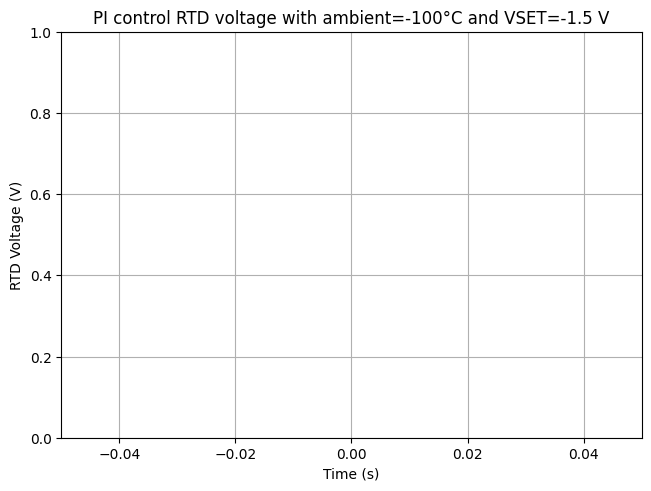

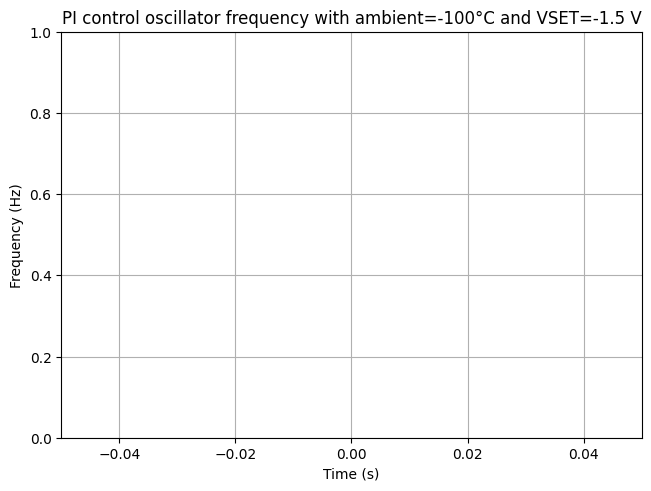

In [ ]:
# Use this to print the formatting of all of your plots - not called during tests
# This is why plot initializations are separate

plot_amb_Ts = [-100]
plot_RSETs = [-1.5]

def initialize_all_plots(amb_Ts, RSETs):
    for amb_T in amb_Ts:
        for RSET in RSETs:
            fig, ax = heat_on_off_plot_VRTD_init(rf"PI control RTD voltage with ambient={amb_T}°C and RSET={RSET} $\Omega$", "Time (s)", f"RTD Voltage (V)")
            fig, ax = heat_on_off_plot_freq_init(rf"PI control oscillator frequency with ambient={amb_T}°C and RSET={RSET} $\Omega$", "Time (s)", f"Frequency (Hz)")
            pass # "pass" allows you to comment out the above line without python yelling at you for the loop doing nothing
    plt.show()

initialize_all_plots(plot_amb_Ts, plot_RSETs)

<h3>* Generate Experimental Plots </h3>

In [15]:
# HOW TO COMBINE TWO
# run1 = "Temperature_Sweep_1_[Heat Stays On]" # Manually set
# run2 = "Temperature_Sweep_2_[Repeating_-28C]" # Manually set
# read_dir_1 = os.path.join(f"{DEVICE_NAME}_Results", date, run1) 
# read_dir_2 = os.path.join(f"{DEVICE_NAME}_Results", date, run2) 
# data_1, [plot_amb_Ts_1, plot_RSETs_1] = ICASL.read_tree_csv(read_dir_1, ["temp", "RSET"])
# data_2, [plot_amb_Ts_2, plot_RSETs_2] = ICASL.read_tree_csv(read_dir_2, ["temp", "RSET"])

# data = {}
# for temp in [-25, -30]:
#     data[temp] = data_1[temp]
# for temp in [-28,-40, -50, -75, -100]:
#     data[temp] = data_2[temp]

# Save this combination of data into a single .csv
# df_final = {}
# first = True
# for temp in plot_amb_Ts:
#     for RSET in plot_RSETs:
#         df1 = ICASL.fix_dataframe(data[temp][RSET])
#         if first:
#             df_final = pd.concat([df1], ignore_index=True)
#             first = False
#         else:
#             df_final = pd.concat([df_final, df1], ignore_index=True)

# # Sort in order experiment was run
# df_final.sort_values(by='ambient_temp', ascending=False, inplace=True)
# print(df_final)
# store_data(df_final, plot_dir, RSET, "heat_stays_on_combined_data")

#### Heat On/Off (Analog Control Loop)

In [ ]:
# 9-28-2026 
execute_cells_by_tag('init') 

DEVICE_NAME = "Analog_Board_Prototype"
date = "2026-09-29" # Manually set 
run = "Single_Temp_1_[-100°C][Heat_on_off][Cold_Start]" # Manually set
read_dir = os.path.join(f"{DEVICE_NAME}_Results", date, run) 
plots_dir = os.path.join(f"{DEVICE_NAME}_Results", date, "Plots_Generated_Later") # Make sure this doesn't overwrite anything important
LOG = True

def plot_heat_on_off(write_dir, temp, RSET, start, end, full_test=False):
    data, [plot_amb_Ts, plot_RSETs] = ICASL.read_tree_csv(read_dir, ["temp", "RSET"])
    data[temp][RSET] = ICASL.limit_data(data[temp][RSET], "time", start, end)
    heat_on_off_plots(data, write_dir, plot_amb_Ts, plot_RSETs)
    if full_test:
        for amb_T in plot_amb_Ts:
            for RSET in plot_RSETs:
                df = data[amb_T][RSET] 
                # This calculation only works for the full range of data -- heat turns on and off, settles both time
                calc_time_constants_from_full_on_off_test(df, plots_dir, temp, RSET)

data, [plot_amb_Ts, plot_RSETs] = ICASL.read_tree_csv(read_dir, ["temp", "RSET"])
print(plot_amb_Ts) ; print(plot_RSETs) ; print(data)

# Plot
temp = -100
RSET = 922

# Time range for PWM comparison (matching PWM's time ranges):
#start=0 ; end=11       # Heater starts off
#start=5 ; end=95     # Heater turns on
#start=350 ; end=420    # Heating Settled
#start=420 ; end=690    # Heater turns off
#start=680 ; end=969    # Heater stays off
#start=0 ; end=1360      # Full range

# Time range for best visuals (matching PWM's time ranges):
#start=0 ; end=11       # Heater starts off
#start=5 ; end=95     # Heater turns on
#start=350 ; end=420    # Heating Settled
#start=420 ; end=690    # Heater turns off
#start=680 ; end=969    # Heater stays off
#start=0 ; end=1360      # Full range

write_dir = os.path.join(plots_dir, "Heat_On_Off", "Full_Range")
plot_heat_on_off(write_dir, temp, RSET, start=0, end=1360, full_test=True)
write_dir = os.path.join(plots_dir, "Heat_On_Off", "Heat_Turning_On")
plot_heat_on_off(write_dir, temp, RSET, start=5, end=95)
write_dir = os.path.join(plots_dir, "Heat_On_Off", "Heat_Turning_Off")
plot_heat_on_off(write_dir, temp, RSET, start=420, end=690)
write_dir = os.path.join(plots_dir, "Heat_On_Off", "Heating_Settled")
plot_heat_on_off(write_dir, temp, RSET, start=350, end=420)

----------------------------------
Imported Libraries
ICASL is loaded!
Initialized Constants:
RUN_TIME = 540
NUM_MEASUREMENTS_BEFORE_HEAT = 20
GLOBAL_RSET = 922
GLOBAL_TEMPS = [-25, -30, -50, -75, -100, -125, -150]
Initialized 'Establish Connection'
Initialized Equipment Interfacing Functions
Initialized Plotting Default Styling
Initialized Plotting Functions
Initialized Full Procedure
----------------------------------
Layer of keys 1 for temp: [-100]
Layer of keys 2 for RSET: [922]
Final dataframe columns: ['time', 'heater_status', 'ambient_temp', 'VRTD', 'V1mA', 'VSET', 'heat_IDD']

[-100]
[922]
{-100: {922:             time  heater_status  ambient_temp      VRTD      V1mA      VSET  \
0       0.000006              0       -100.04  1.183818  1.995322  1.930401   
1       0.162480              0       -100.04  1.183888  1.995413  1.930539   
2       0.602545              0        -99.97  1.183930  1.995488  1.930569   
3       0.971587              0        -99.97  1.183971  1.995478

<>:36: SyntaxWarning: invalid escape sequence '\O'
C:\Users\spnew\AppData\Local\Temp\ipykernel_35984\922550930.py:36: SyntaxWarning: invalid escape sequence '\O'
  fig, ax = heat_on_off_plot_general_init(rf"Heat On/Off RTD Resistance with ambient={amb_T}°C and RSET={RSET} $\Omega$", "Time (s)", f"RTD Resistance ($\Omega$)")
<>:34: SyntaxWarning: invalid escape sequence '\O'
C:\Users\spnew\AppData\Local\Temp\ipykernel_35984\3925596144.py:34: SyntaxWarning: invalid escape sequence '\O'
  fig, ax = heat_stays_on_plot_general_init(rf"Heat Stays On RTD Resistance with RSET={RSET} $\Omega$", "Ambient Temperature (°C)", f"RTD Resistance ($\Omega$)")


Initial time: 6.232921899994835, Initial value: 0.593128825
Target value: 0.81488724282 (63.2%)
Settled time: 415.5504867000273, Settled value: 0.9440123975
Crossing time: 13.43534790002741, Crossing value: 0.81553933
Rising time constant for ambient temp. -100 and RSET 922: 7.202426000032574
Initial time: 426.14612020005006, Initial value: 0.943405235
Target value: 0.72209919014 (63.2%)
Settled time: 835.8594888000516, Settled value: 0.5932374425
Crossing time: 439.9583055999829, Crossing value: 0.72153031
Falling time constant for ambient temp. -100 and RSET 922: 13.812185399932844
Layer of keys 1 for temp: [-100]
Layer of keys 2 for RSET: [922]
Final dataframe columns: ['time', 'heater_status', 'ambient_temp', 'VRTD', 'V1mA', 'VSET', 'heat_IDD']

Layer of keys 1 for temp: [-100]
Layer of keys 2 for RSET: [922]
Final dataframe columns: ['time', 'heater_status', 'ambient_temp', 'VRTD', 'V1mA', 'VSET', 'heat_IDD']

Layer of keys 1 for temp: [-100]
Layer of keys 2 for RSET: [922]
Final 

#### Heat Stays On (Analog Control Loop)

In [ ]:
execute_cells_by_tag('init') 

DEVICE_NAME = "Analog_Board_Prototype"
date = "2026-09-29" # Manually set 
run = "Temperature_Sweep_2_[Heat Stays On]" # Manually set
read_dir = os.path.join(f"{DEVICE_NAME}_Results", date, run)  
plot_dir = os.path.join(f"{DEVICE_NAME}_Results", date, "Plots_Generated_Later")
write_dir = os.path.join(plot_dir, "Heat_Stays_On") # Make sure this doesn't overwrite anything important
LOG = True

data, [plot_amb_Ts, plot_RSETs] = ICASL.read_tree_csv(read_dir, ["temp", "RSET"])

plot_amb_Ts = ICASL.clean_list(plot_amb_Ts)
plot_RSETs = ICASL.clean_list(plot_RSETs)

print(plot_amb_Ts) ; print(plot_RSETs) ; print(data)

# Plot
heat_stays_on_plots(data, write_dir, plot_amb_Ts, plot_RSETs)

----------------------------------
Imported Libraries
ICASL is loaded!
Initialized Constants:
RUN_TIME = 540
NUM_MEASUREMENTS_BEFORE_HEAT = 20
GLOBAL_RSET = 922
GLOBAL_TEMPS = [-25, -30, -50, -75, -100, -125, -150]
Initialized 'Establish Connection'
Initialized Equipment Interfacing Functions
Initialized Plotting Default Styling
Initialized Plotting Functions
Initialized Full Procedure
----------------------------------
Layer of keys 1 for temp: [-100, -75, -50, -20]
Layer of keys 2 for RSET: [922]
Final dataframe columns: ['ambient_temp', 'VRTD', 'V1mA', 'VSET', 'heat_IDD']

[-100, -75, -50, -20]
[922]
{-100: {922:    ambient_temp      VRTD      V1mA      VSET  heat_IDD
0         -99.9  1.887556  1.992403  1.928719     0.416}, -20: {922:    ambient_temp      VRTD      V1mA      VSET  heat_IDD
0       -19.767  1.911445  1.994654  1.931594         0}, -50: {922:    ambient_temp      VRTD      V1mA      VSET  heat_IDD
0         -50.0  1.889823  1.992694  1.928634     0.324}, -75: {922:  

<>:36: SyntaxWarning: invalid escape sequence '\O'
C:\Users\spnew\AppData\Local\Temp\ipykernel_35984\922550930.py:36: SyntaxWarning: invalid escape sequence '\O'
  fig, ax = heat_on_off_plot_general_init(rf"Heat On/Off RTD Resistance with ambient={amb_T}°C and RSET={RSET} $\Omega$", "Time (s)", f"RTD Resistance ($\Omega$)")
<>:34: SyntaxWarning: invalid escape sequence '\O'
C:\Users\spnew\AppData\Local\Temp\ipykernel_35984\3925596144.py:34: SyntaxWarning: invalid escape sequence '\O'
  fig, ax = heat_stays_on_plot_general_init(rf"Heat Stays On RTD Resistance with RSET={RSET} $\Omega$", "Ambient Temperature (°C)", f"RTD Resistance ($\Omega$)")


#### Heat On/Off PWM Control Loop

In [ ]:
# 4-02-2026. Heating from -100 to -28
execute_cells_by_tag('init') 

DEVICE_NAME = "Prototype_Board"
date = "2026-04-02" # Manually set 
run = os.path.join("Single_Temp_2_[-100°C][Cold_Start][Heat_On_Off]", "Cold_start") # Manually set
read_dir = os.path.join(f"{DEVICE_NAME}_Results", date, run) 
plots_dir = os.path.join(f"{DEVICE_NAME}_Results", date, "Plots_Generated_Later") # Make sure this doesn't overwrite anything important
LOG = True

def plot_heat_on_off(write_dir, temp, VSET, start, end, full_test=False):
    data, [plot_amb_Ts, plot_VSETs] = ICASL.read_tree_csv(read_dir, ["temp", "VSET"])
    data[temp][VSET] = ICASL.limit_data(data[temp][VSET], "time", start, end)
    heat_on_off_plots(data, write_dir, plot_amb_Ts, plot_VSETs)
    if full_test:
        for amb_T in plot_amb_Ts:
            for VSET in plot_VSETs:
                df = data[amb_T][VSET] 
                # This calculation only works for the full range of data -- heat turns on and off, settles both time
                calc_time_constants_from_full_on_off_test(df, plots_dir, temp, VSET)

data, [plot_amb_Ts, plot_VSETs] = ICASL.read_tree_csv(read_dir, ["temp", "VSET"])
print(plot_amb_Ts) ; print(plot_VSETs) ; print(data)

# Plot
temp = -100
VSET = -0.924

# Time range:
#start=0 ; end=11       # Heater starts off
#start=10 ; end=100     # Heater turns on
#start=480 ; end=550    # Heating Settled
#start=530 ; end=800    # Heater turns off
#start=0 ; end=1090      # Full range

write_dir = os.path.join(plots_dir, "Heat_On_Off", "Full_Range")
plot_heat_on_off(write_dir, temp, VSET, start=0, end=1090, full_test=True)
write_dir = os.path.join(plots_dir, "Heat_On_Off", "Heat_Turning_On")
plot_heat_on_off(write_dir, temp, VSET, start=10, end=100)
write_dir = os.path.join(plots_dir, "Heat_On_Off", "Heat_Turning_Off")
plot_heat_on_off(write_dir, temp, VSET, start=530, end=800)
write_dir = os.path.join(plots_dir, "Heat_On_Off", "Heating_Settled")
plot_heat_on_off(write_dir, temp, VSET, start=480, end=550)

#### Heat Stays On PWM Control Loop

In [ ]:
execute_cells_by_tag('init') 

# Manual use - Not called during procedure

DEVICE_NAME = "Prototype_Board"
date = "2026-04-02" # Manually set 
run1 = "Temperature_Sweep_1_[Heat Stays On]" # Manually set
run2 = "Temperature_Sweep_2_[Repeating_-28C]" # Manually set
read_dir_1 = os.path.join(f"{DEVICE_NAME}_Results", date, run1) 
read_dir_2 = os.path.join(f"{DEVICE_NAME}_Results", date, run2) 
plot_dir = os.path.join(f"{DEVICE_NAME}_Results", date, "Plots_Generated_Later")
write_dir = os.path.join(plot_dir, "Heat_Stays_On") # Make sure this doesn't overwrite anything important
LOG = True

# Data from many smaller csv's within two different run directories is combined.

data_1, [plot_amb_Ts_1, plot_VSETs_1] = ICASL.read_tree_csv(read_dir_1, ["temp", "VSET"])
data_2, [plot_amb_Ts_2, plot_VSETs_2] = ICASL.read_tree_csv(read_dir_2, ["temp", "VSET"])

data = {}
for temp in [-25, -30]:
    data[temp] = data_1[temp]
for temp in [-28,-40, -50, -75, -100]:
    data[temp] = data_2[temp]
plot_amb_Ts = ICASL.clean_list(plot_amb_Ts_1 + plot_amb_Ts_2)
plot_VSETs = ICASL.clean_list(plot_VSETs_1 + plot_VSETs_2)

print(plot_amb_Ts) ; print(plot_VSETs) ; print(data)

# Plot
heat_stays_on_plots(data, write_dir, plot_amb_Ts, plot_VSETs)

# Save this combination of data into a single .csv
df_final = {}
first = True
for temp in plot_amb_Ts:
    for VSET in plot_VSETs:
        df1 = ICASL.fix_dataframe(data[temp][VSET])
        if first:
            df_final = pd.concat([df1], ignore_index=True)
            first = False
        else:
            df_final = pd.concat([df_final, df1], ignore_index=True)
# Fix duty cycle
df_final.loc[df_final['duty_cycle'] > 100, 'duty_cycle'] = 100
df_final['duty_cycle'] = 100 - df_final['duty_cycle']
# Sort in order experiment was run
df_final.sort_values(by='ambient_temp', ascending=False, inplace=True)
print(df_final)
store_data(df_final, plot_dir, VSET, "heat_stays_on_combined_data")

#### New Plotting Functions

In [19]:
def heat_on_off_plot_RTD_temperature_analog_combined(ax, df, RSET):
    RTD_resistances = (df["VRTD"] / 2) / (df["V1mA"] / 2000) # Analog VRTD is recorded at twice the scale used by the RTD calibration.

    RTD_MAP_PATH = os.path.join("..", "PWM_Control_Loop_Prototype", "Device_Characterizations", "RTD_Phase_1_Board.csv")
    RTD_table = ICASL.read_csv(RTD_MAP_PATH)
    R = np.flip(RTD_table["Resistance"].values) # Flip so it's in ascending order. Required for this interpolation function.
    T = np.flip(RTD_table["Temperature"].values)
    RTD_inter = make_interp_spline(R, T, k=1) # Linear interpolation
    ax.plot(df["time"], RTD_inter(RTD_resistances), label=rf"Analog")
    return ax

def heat_on_off_plot_RTD_temperature_PWM_combined(ax, df, VSET):
    RTD_resistances = df["VRTD"] / (df["V1mA"] / 2000) # 2V = 1mA. V1mA comes from 1mA current through 10 ohm resistor, gained by 20.

    RTD_MAP_PATH = os.path.join("..", "PWM_Control_Loop_Prototype", "Device_Characterizations", "RTD_Phase_1_Board.csv")
    RTD_table = ICASL.read_csv(RTD_MAP_PATH)
    R = np.flip(RTD_table["Resistance"].values) # Flip so it's in ascending order. Required for this interpolation function.
    T = np.flip(RTD_table["Temperature"].values)
    RTD_inter = make_interp_spline(R, T, k=1) # Linear interpolation
    ax.plot(df["time"], RTD_inter(RTD_resistances), label=f"PWM")
    return ax

def heat_stays_on_plot_RTD_temperature_analog_combined(ax, data, amb_Ts, RSET):
    VRTDs = extract_across_temperature(data, amb_Ts, RSET, "VRTD")
    V1mAs = extract_across_temperature(data, amb_Ts, RSET, "V1mA")
    RTD_resistances = [(VRTD / 2) / (V1mA / 2000) for VRTD, V1mA in zip(VRTDs, V1mAs)] # Analog VRTD is recorded at twice the scale used by the RTD calibration.

    RTD_MAP_PATH = os.path.join("..", "PWM_Control_Loop_Prototype", "Device_Characterizations", "RTD_Phase_1_Board.csv")
    RTD_table = ICASL.read_csv(RTD_MAP_PATH)
    R = np.flip(RTD_table["Resistance"].values) # Flip so it's in ascending order. Required for this interpolation function.
    T = np.flip(RTD_table["Temperature"].values)
    RTD_inter = make_interp_spline(R, T, k=1) # Linear interpolation
    ax.plot(amb_Ts, RTD_inter(RTD_resistances), label=rf"Analog", marker='o')
    return ax


def heat_stays_on_plot_RTD_temperature_PWM_combined(ax, data, amb_Ts, VSET):
    VRTDs = extract_across_temperature(data, amb_Ts, VSET, "VRTD")
    V1mAs = extract_across_temperature(data, amb_Ts, VSET, "V1mA")
    RTD_resistances = [VRTD / (V1mA / 2000) for VRTD, V1mA in zip(VRTDs, V1mAs)] # 2V = 1mA. V1mA comes from 1mA current through 10 ohm resistor, gained by 20.

    RTD_MAP_PATH = os.path.join("..", "PWM_Control_Loop_Prototype", "Device_Characterizations", "RTD_Phase_1_Board.csv")
    RTD_table = ICASL.read_csv(RTD_MAP_PATH)
    R = np.flip(RTD_table["Resistance"].values) # Flip so it's in ascending order. Required for this interpolation function.
    T = np.flip(RTD_table["Temperature"].values)
    RTD_inter = make_interp_spline(R, T, k=1) # Linear interpolation
    ax.plot(amb_Ts, RTD_inter(RTD_resistances), label=f"PWM", marker='o')
    return ax

#### Combined Heat On/Off

In [20]:
execute_cells_by_tag('init')

root = ".."
amb_T = -100
RSET = 922
VSET = -0.924

analog_read_dir = os.path.join(root, "Analog_Control_Loop_Prototype", "Analog_Board_Prototype_Results", "2026-09-29", "Single_Temp_1_[-100°C][Heat_on_off][Cold_Start]")
pwm_read_dir = os.path.join(root, "PWM_Control_Loop_Prototype", "Prototype_Board_Results", "2026-04-02", "Single_Temp_2_[-100°C][Cold_Start][Heat_On_Off]", "Cold_Start")
plots_dir = os.path.join(root, "Comparing_Control_Loops", "Plots_Generated_Later")

analog_data, _ = ICASL.read_tree_csv(analog_read_dir, ["temp", "RSET"])
pwm_data, _ = ICASL.read_tree_csv(pwm_read_dir, ["temp", "VSET"])

plot_phases = [
    ("turning_on", "Heater Turning On", 5, 95, 10, 100),
    ("settled", "Heating Settled", 350, 420, 480, 550),
]

for phase_name, phase_title, analog_start, analog_end, pwm_start, pwm_end in plot_phases:
    analog_df = ICASL.limit_data(analog_data[amb_T][RSET], "time", analog_start, analog_end).copy()
    pwm_df = ICASL.limit_data(pwm_data[amb_T][VSET], "time", pwm_start, pwm_end).copy()
    analog_df["time"] -= analog_start
    pwm_df["time"] -= pwm_start

    fig, ax = heat_on_off_plot_general_init(rf"Heat On/Off RTD Temperature: {phase_title} at {amb_T}°C", "Time Since Start (s)", "RTD Temperature (°C)")
    ax = heat_on_off_plot_RTD_temperature_analog_combined(ax, analog_df, RSET)
    ax = heat_on_off_plot_RTD_temperature_PWM_combined(ax, pwm_df, VSET)
    local_finish_plot(fig, ax, plots_dir, f"heat_on_off_{phase_name}_RTD_Temperature_@_amb_T={amb_T}.png")

    if phase_name == "settled":
        analog_df = ICASL.limit_data(analog_data[amb_T][RSET], "time", analog_start, analog_end).copy()
        pwm_df = ICASL.limit_data(pwm_data[amb_T][VSET], "time", pwm_start, pwm_end).copy()
        analog_df["time"] -= analog_start
        pwm_df["time"] -= pwm_start

        fig, ax = heat_on_off_plot_general_init("Heat On/Off RTD Temperature: Heating Settled (Mean-Aligned)", "Time Since Start (s)", "RTD Temperature (°C)")
        ax = heat_on_off_plot_RTD_temperature_analog_combined(ax, analog_df, RSET)
        ax = heat_on_off_plot_RTD_temperature_PWM_combined(ax, pwm_df, VSET)
        analog_line, pwm_line = ax.lines
        analog_temperatures = np.asarray(analog_line.get_ydata())
        pwm_temperatures = np.asarray(pwm_line.get_ydata())
        analog_shift = np.mean(pwm_temperatures) - np.mean(analog_temperatures)
        analog_line.set_ydata(analog_temperatures + analog_shift)
        analog_line.set_label(f"Analog (shifted {analog_shift:+.1f}°C)")
        aligned_temperatures = np.concatenate([analog_line.get_ydata(), pwm_temperatures])
        y_min = np.min(aligned_temperatures)
        y_max = np.max(aligned_temperatures)
        y_padding = max((y_max - y_min) * 0.1, 0.01)
        ax.set_ylim(y_min - y_padding, y_max + y_padding)
        ax.legend()
        local_finish_plot(fig, ax, plots_dir, f"heat_on_off_settled_RTD_Temperature_mean_aligned_@_amb_T={amb_T}.png")

----------------------------------
Imported Libraries
ICASL is loaded!
Initialized Constants:
RUN_TIME = 540
NUM_MEASUREMENTS_BEFORE_HEAT = 20
GLOBAL_RSET = 922
GLOBAL_TEMPS = [-25, -30, -50, -75, -100, -125, -150]
Initialized Plotting Default Styling
Initialized Plotting Functions
----------------------------------
Layer of keys 1 for temp: [-100]
Layer of keys 2 for RSET: [922]
Final dataframe columns: ['time', 'heater_status', 'ambient_temp', 'VRTD', 'V1mA', 'VSET', 'heat_IDD']

Layer of keys 1 for temp: [-100]
Layer of keys 2 for VSET: [-0.924]
Final dataframe columns: ['time', 'heater_status', 'ambient_temp', 'VRTD', 'V1mA', 'frequency', 'duty_cycle', 'pulse_height', 'heat_IDD', 'heat_ISS']



<>:36: SyntaxWarning: invalid escape sequence '\O'
C:\Users\spnew\AppData\Local\Temp\ipykernel_22644\922550930.py:36: SyntaxWarning: invalid escape sequence '\O'
  fig, ax = heat_on_off_plot_general_init(rf"Heat On/Off RTD Resistance with ambient={amb_T}°C and RSET={RSET} $\Omega$", "Time (s)", f"RTD Resistance ($\Omega$)")
<>:34: SyntaxWarning: invalid escape sequence '\O'
C:\Users\spnew\AppData\Local\Temp\ipykernel_22644\3925596144.py:34: SyntaxWarning: invalid escape sequence '\O'
  fig, ax = heat_stays_on_plot_general_init(rf"Heat Stays On RTD Resistance with RSET={RSET} $\Omega$", "Ambient Temperature (°C)", f"RTD Resistance ($\Omega$)")


#### Combined Heat Stays On

In [16]:
execute_cells_by_tag('init')

# Plots the Heat Stays On "RTD Temp" data
root = ".."
RSET = 922
VSET = -0.924
amb_Ts = [-100, -75, -50]
analog_read_dir = os.path.join(root, "Analog_Control_Loop_Prototype", "Analog_Board_Prototype_Results", "2026-09-29", "Temperature_Sweep_2_[Heat Stays On]")
pwm_read_dir = os.path.join(root, "PWM_Control_Loop_Prototype", "Prototype_Board_Results", "2026-04-02", "Temperature_Sweep_2_[Repeating_-28C]")
plots_dir = os.path.join(root, "Comparing_Control_Loops", "Plots_Generated_Later")

analog_data, _ = ICASL.read_tree_csv(analog_read_dir, ["temp", "RSET"])
pwm_data, _ = ICASL.read_tree_csv(pwm_read_dir, ["temp", "VSET"])

fig, ax = heat_stays_on_plot_general_init("Heat Stays On RTD Temperature", "Ambient Temperature (°C)", "RTD Temperature (°C)")
ax = heat_stays_on_plot_RTD_temperature_analog_combined(ax, analog_data, amb_Ts, RSET)
ax = heat_stays_on_plot_RTD_temperature_PWM_combined(ax, pwm_data, amb_Ts, VSET)
local_finish_plot(fig, ax, plots_dir, "heat_stays_on_RTD_Temperature.png")

----------------------------------
Imported Libraries
ICASL is loaded!
Initialized Constants:
RUN_TIME = 540
NUM_MEASUREMENTS_BEFORE_HEAT = 20
GLOBAL_RSET = 922
GLOBAL_TEMPS = [-25, -30, -50, -75, -100, -125, -150]
Initialized Plotting Default Styling
Initialized Plotting Functions
----------------------------------
Layer of keys 1 for temp: [-100, -75, -50, -20]
Layer of keys 2 for RSET: [922]
Final dataframe columns: ['ambient_temp', 'VRTD', 'V1mA', 'VSET', 'heat_IDD']

Layer of keys 1 for temp: [-100, -75, -50, -40, -28]
Layer of keys 2 for VSET: [-0.924]
Final dataframe columns: ['ambient_temp', 'VRTD', 'V1mA', 'frequency', 'standard_deviation', 'duty_cycle', 'pulse_height', 'heat_IDD', 'heat_ISS']



<>:36: SyntaxWarning: invalid escape sequence '\O'
C:\Users\spnew\AppData\Local\Temp\ipykernel_22644\922550930.py:36: SyntaxWarning: invalid escape sequence '\O'
  fig, ax = heat_on_off_plot_general_init(rf"Heat On/Off RTD Resistance with ambient={amb_T}°C and RSET={RSET} $\Omega$", "Time (s)", f"RTD Resistance ($\Omega$)")
<>:34: SyntaxWarning: invalid escape sequence '\O'
C:\Users\spnew\AppData\Local\Temp\ipykernel_22644\3925596144.py:34: SyntaxWarning: invalid escape sequence '\O'
  fig, ax = heat_stays_on_plot_general_init(rf"Heat Stays On RTD Resistance with RSET={RSET} $\Omega$", "Ambient Temperature (°C)", f"RTD Resistance ($\Omega$)")
